# MySumiller: calidad del catálogo y exploración de X-Wines

Memoria breve de EDA. Se analiza el catálogo completo de 100.646 vinos y una muestra uniforme reproducible de hasta 100.000 valoraciones, seleccionada por bloques con semilla fija. Para obtenerla se recorre el CSV de ratings en streaming, pero solo se conserva y analiza la muestra. Las conclusiones sobre ratings se limitan a esa muestra y no se presentan como agregaciones de los 21 millones.

In [7]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, SVG, Markdown, display

ROOT = Path.cwd()
if ROOT.name != 'data-pipeline':
    ROOT = ROOT / 'data-pipeline'
sys.path.insert(0, str(ROOT / 'src'))
from wine_pipeline.cli import run_pipeline

METRICS_PATH = ROOT / 'reports' / 'summary' / 'eda_metrics.json'
if not METRICS_PATH.exists():
    run_pipeline('all', rating_limit=100_000)
metrics = json.loads(METRICS_PATH.read_text(encoding='utf-8'))
wine_profile = json.loads((ROOT / 'reports' / 'data_quality' / 'wines_profile.json').read_text(encoding='utf-8'))
rating_profile = json.loads((ROOT / 'reports' / 'data_quality' / 'ratings_sample_profile.json').read_text(encoding='utf-8'))

def display_figure(stem):
    base = ROOT / 'reports' / 'figures' / stem
    png_path, svg_path = base.with_suffix('.png'), base.with_suffix('.svg')
    if png_path.exists():
        display(Image(filename=str(png_path)))
    elif svg_path.exists():
        display(SVG(filename=str(svg_path)))
    else:
        raise FileNotFoundError(f'No existe la figura: {base}')

print(f"Catálogo completo: {wine_profile['row_count']:,} vinos | Ratings: {rating_profile['row_count']:,} muestra aleatoria (semilla {rating_profile['scope']['seed']})")

Catálogo completo: 100,646 vinos | Ratings: 100,000 muestra aleatoria (semilla 42)


## 1. Introducción y contexto
MySumiller necesita una base de catálogo consistente y trazable antes de explorar recomendaciones. X-Wines aporta metadatos de vinos y puntuaciones externas; estas últimas conservan su fuente y no representan valoraciones propias de MySumiller.

## 2. Objetivo y preguntas
1. ¿Qué atributos del catálogo están menos documentados?
2. ¿Cómo se distribuyen ABV y las puntuaciones del subconjunto disponible?
3. ¿Cómo cambia la incertidumbre descriptiva al comparar vinos y usuarios con distinto número de ratings?
4. ¿Qué extremos estadísticos y posibles duplicados requieren revisión?

## 3. Fuente y descripción
X-Wines Dataset 1.0 (enero de 2023), catálogo de 100.646 registros y CSV de valoraciones de aproximadamente 21 millones de filas. La referencia asociada es de Azambuja, Morais y Filipe (2023), *Big Data and Cognitive Computing*, 7(1), artículo 20, DOI 10.3390/bdcc7010020. Verificar los términos de uso antes de cualquier integración comercial.

## 4. Alcance, limitaciones y procedencia
Se trabaja con el catálogo completo y una muestra uniforme reproducible de hasta 100.000 ratings, seleccionada por bloques sobre el CSV completo con semilla fija. El fichero se recorre en streaming para muestrear, pero no se cargan ni agregan en memoria los 21 millones de registros. Los originales permanecen en `data/raw/`; los productos analíticos permanecen separados y los ratings se identifican como X-Wines.

## 5. Perfil inicial y calidad
Los perfiles se calcularon sobre el catálogo entero y el subconjunto de ratings descrito. La tabla resume nulos por atributo del catálogo. Un valor ausente no se imputa como cero.

In [3]:
profile_rows = []
for column, item in wine_profile['columns'].items():
    profile_rows.append({'columna': column, 'tipo': item['dtype'], 'nulos': item['null_count'], 'nulos_%': round(item['null_percent'], 2), 'distintos': item['distinct_count']})
display(pd.DataFrame(profile_rows).sort_values('nulos_%', ascending=False))
print('Duplicados exactos de catálogo:', wine_profile['exact_duplicate_rows'])
print('Filas con WineID repetido:', wine_profile['duplicate_identifier_rows'].get('WineID', 0))
print('Duplicados exactos en el subconjunto ratings:', rating_profile['exact_duplicate_rows'])
print('RatingID repetidos en el subconjunto:', rating_profile['duplicate_identifier_rows'].get('RatingID', 0))

,columna,tipo,nulos,nulos_%,distintos
15,Website,str,17867,17.75,19518
0,WineID,int64,0,0.00,100646
1,WineName,str,0,0.00,60981
3,Elaborate,str,0,0.00,22
2,Type,str,0,0.00,6
5,Harmonize,str,0,0.00,900
6,ABV,float64,0,0.00,162
7,Body,str,0,0.00,5
4,Grapes,str,0,0.00,7100
8,Acidity,str,0,0.00,3


Duplicados exactos de catálogo: 0
Filas con WineID repetido: 0
Duplicados exactos en el subconjunto ratings: 0
RatingID repetidos en el subconjunto: 0


## 6. Limpieza y decisiones
Se preservan todos los campos originales e IDs. La limpieza compacta espacios, convierte campos numéricos cuando es posible y parsea listas mediante `ast.literal_eval`; los errores se contabilizan. Las cadenas literales `None` no se convierten a nulo indiscriminadamente. Los límites IQR sirven para inspección, no para borrar vinos o valoraciones. Las candidaturas de duplicados usan atributos de bloqueo y similitud de nombre, sin fusiones automáticas.

## 7. Análisis, distribuciones y extremos
### ABV
¿Qué forma tiene la distribución de graduación y qué valores caen fuera de los límites IQR? El histograma muestra la forma general; el diagrama de caja marca observaciones a investigar, no errores confirmados.

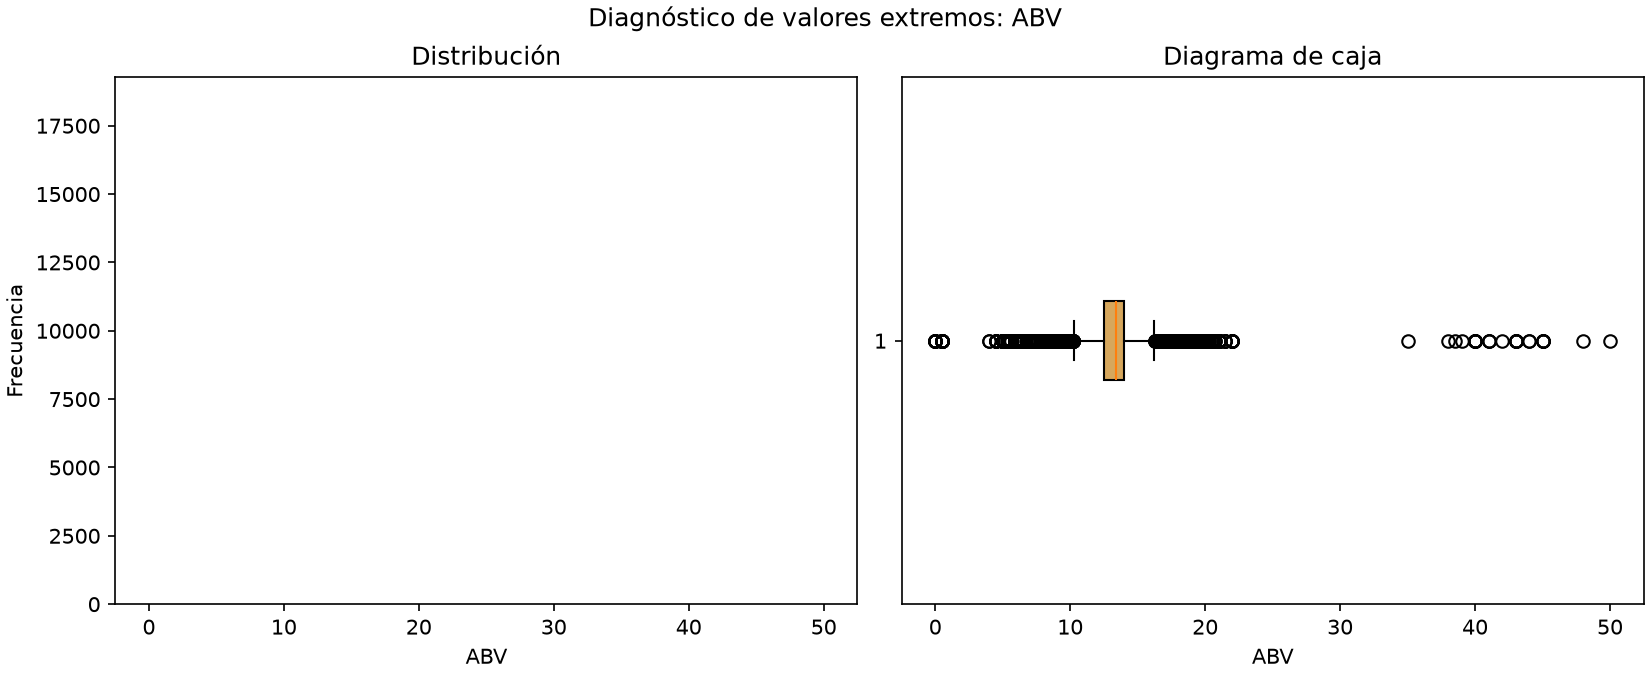

Resumen IQR ABV: {'count': 100646, 'q1': 12.5, 'median': 13.4, 'q3': 14.0, 'iqr': 1.5, 'lower_fence': 10.25, 'upper_fence': 16.25, 'outlier_count': 3462}


In [4]:
display_figure('abv_outliers')
print('Resumen IQR ABV:', metrics['catalog']['numeric_iqr']['ABV'])

### Ratings y actividad
¿Se concentran las puntuaciones en ciertos valores? ¿Se observan usuarios o vinos con frecuencias extremas? La puntuación está acotada y se mantiene en escala original; `log1p` se reserva para recuentos sesgados. La visualización de los recuentos usa una muestra uniforme reproducible de 100.000 ratings.

**Puntuaciones**

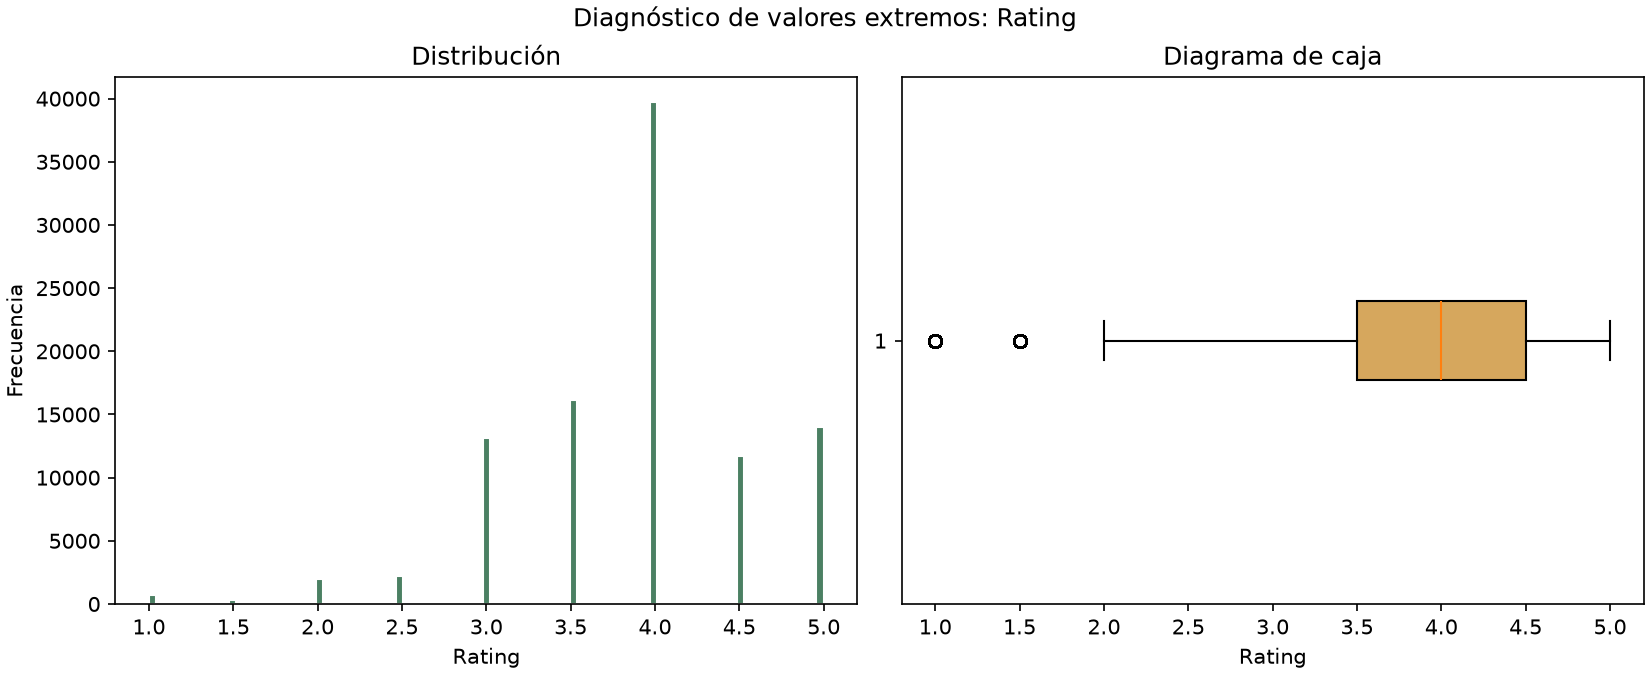

**Ratings por vino**

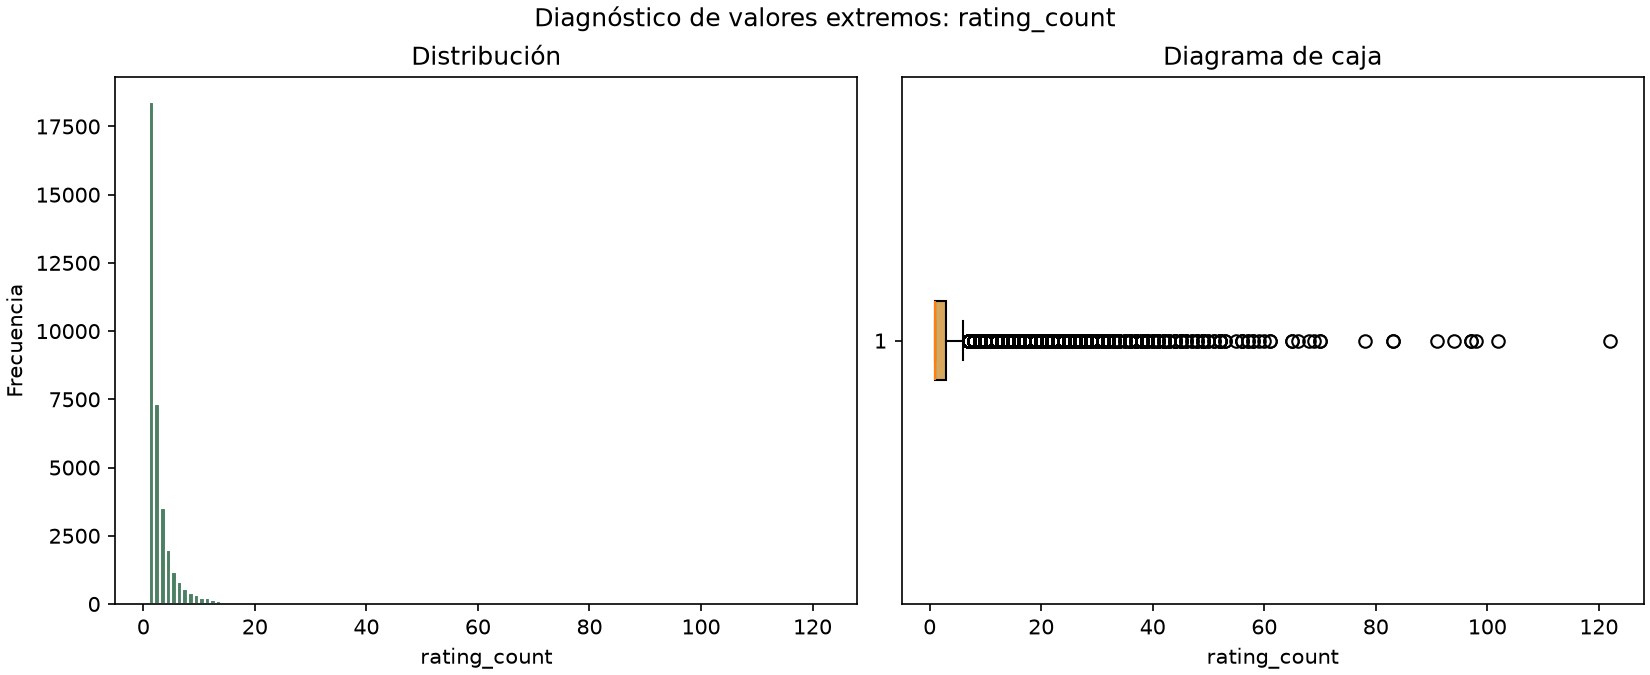

**Ratings por usuario**

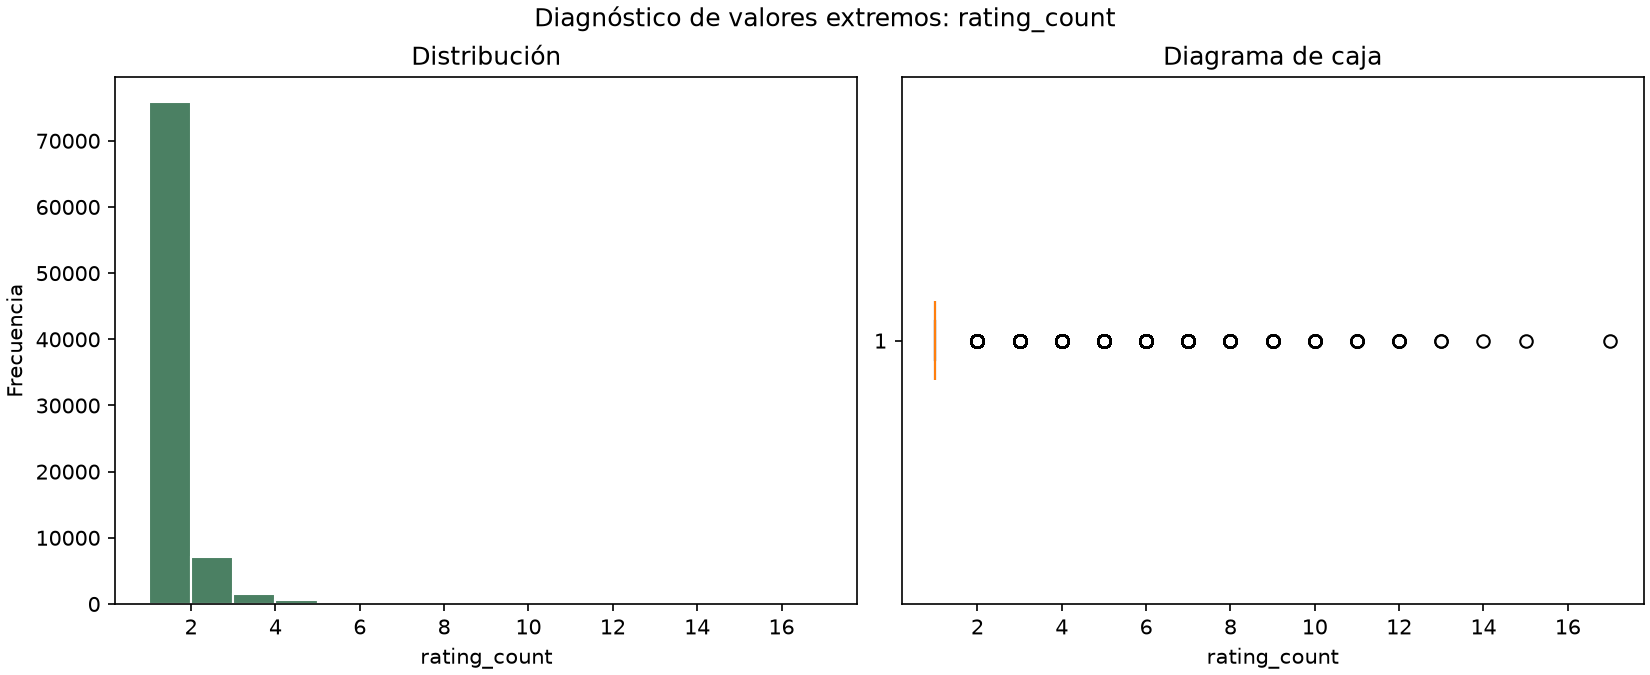

,medida,valor
0,count,100000.000000
1,mean,3.883360
2,std,0.735864
3,min,1.000000
4,25%,3.500000
5,50%,4.000000
6,75%,4.500000
7,max,5.000000


Moda(s): [4.0]
Asimetría: -0.7087247174192898
IQR ratings: {'count': 100000, 'q1': 3.5, 'median': 4.0, 'q3': 4.5, 'iqr': 1.0, 'lower_fence': 2.0, 'upper_fence': 6.0, 'outlier_count': 1028}
Frecuencia por tipo; solo grupos con al menos 20 ratings:


,Type,rating_count,mean_rating,median_rating
0,Red,73347,3.896731,4.0
1,White,18302,3.816987,4.0
2,Sparkling,4499,3.918537,4.0
3,Rosé,2248,3.738434,4.0
4,Dessert,940,4.171277,4.0
5,Dessert/Port,664,4.080572,4.0


In [5]:
for stem, caption in [('ratings_outliers', 'Puntuaciones'), ('sample_ratings_per_wine', 'Ratings por vino'), ('sample_ratings_per_user', 'Ratings por usuario')]:
    display(Markdown(f'**{caption}**'))
    display_figure(stem)
display(pd.DataFrame([
    {'medida': key, 'valor': value}
    for key, value in metrics['ratings_sample']['rating_describe'].items()
]))
print('Moda(s):', metrics['ratings_sample']['rating_mode'])
print('Asimetría:', metrics['ratings_sample']['rating_skew'])
print('IQR ratings:', metrics['ratings_sample']['rating_iqr'])
print('Frecuencia por tipo; solo grupos con al menos 20 ratings:')
display(pd.DataFrame(metrics['ratings_by_category']['Type']))

## 8. Análisis bivariante y multivariante

El análisis bivariante compara ratings y categorías del catálogo. Para ABV frente a rating medio, cada punto representa un vino con al menos cinco ratings en la muestra; la correlación de Spearman describe asociación monotónica, no causalidad. Las barras por tipo y país muestran la media junto al número de ratings; se omiten grupos con menos de 20.

El análisis multivariante usa una fila por vino y las variables ABV, número de uvas, número de añadas, rating medio y número de ratings. Los IDs quedan fuera porque no representan cantidades. La matriz presenta correlaciones de Spearman; el pairplot muestra hasta 2.000 vinos para mantener la figura legible.

**Rating medio por tipo de vino**

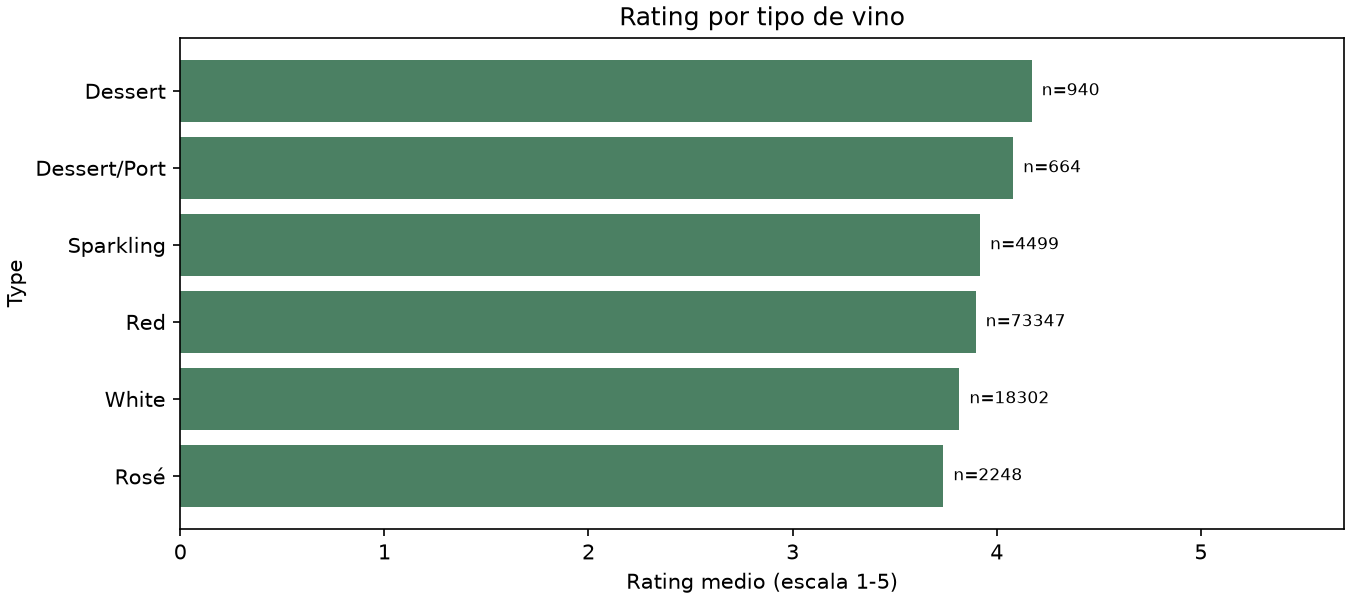

**Rating medio por país**

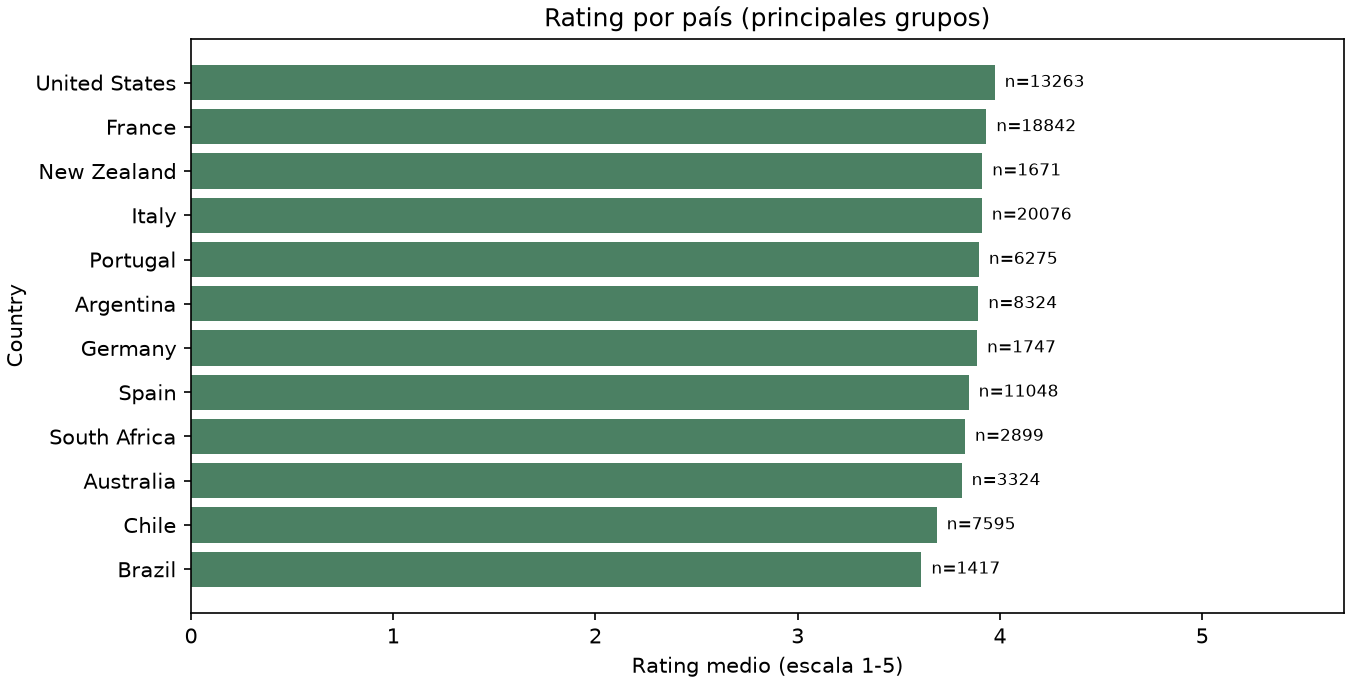

**Relación bivariante: ABV y rating medio**

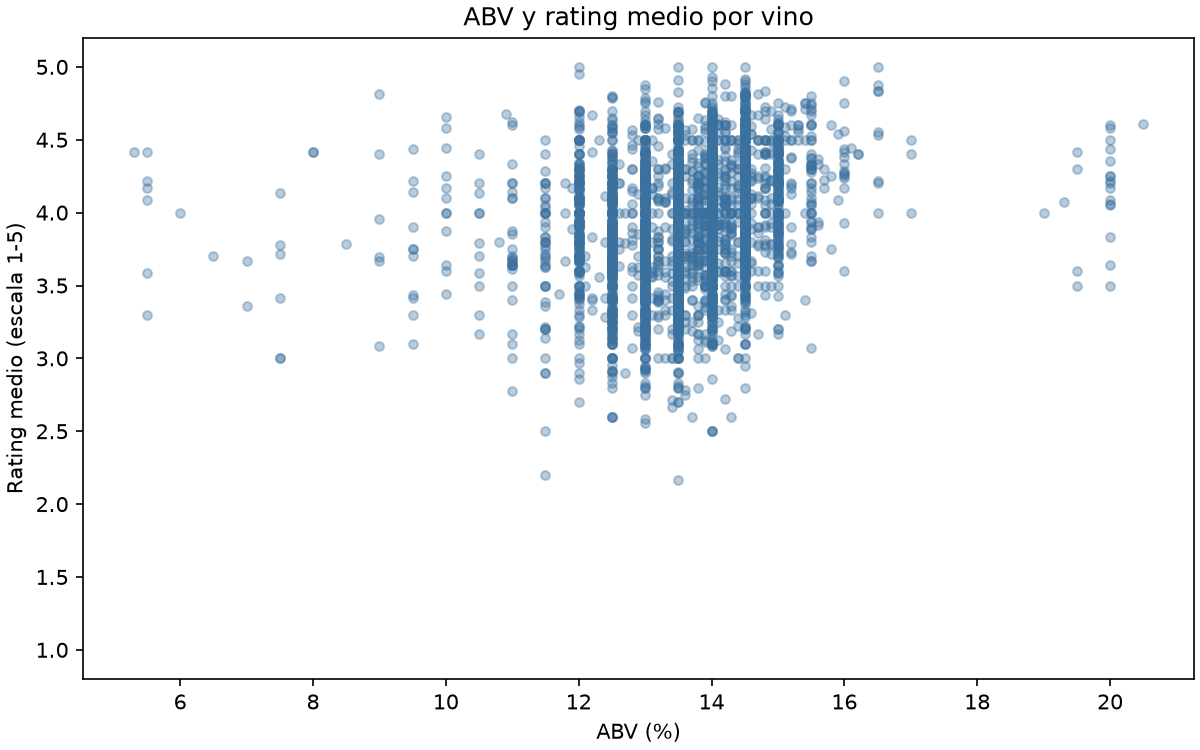

**Heatmap multivariante de correlaciones**

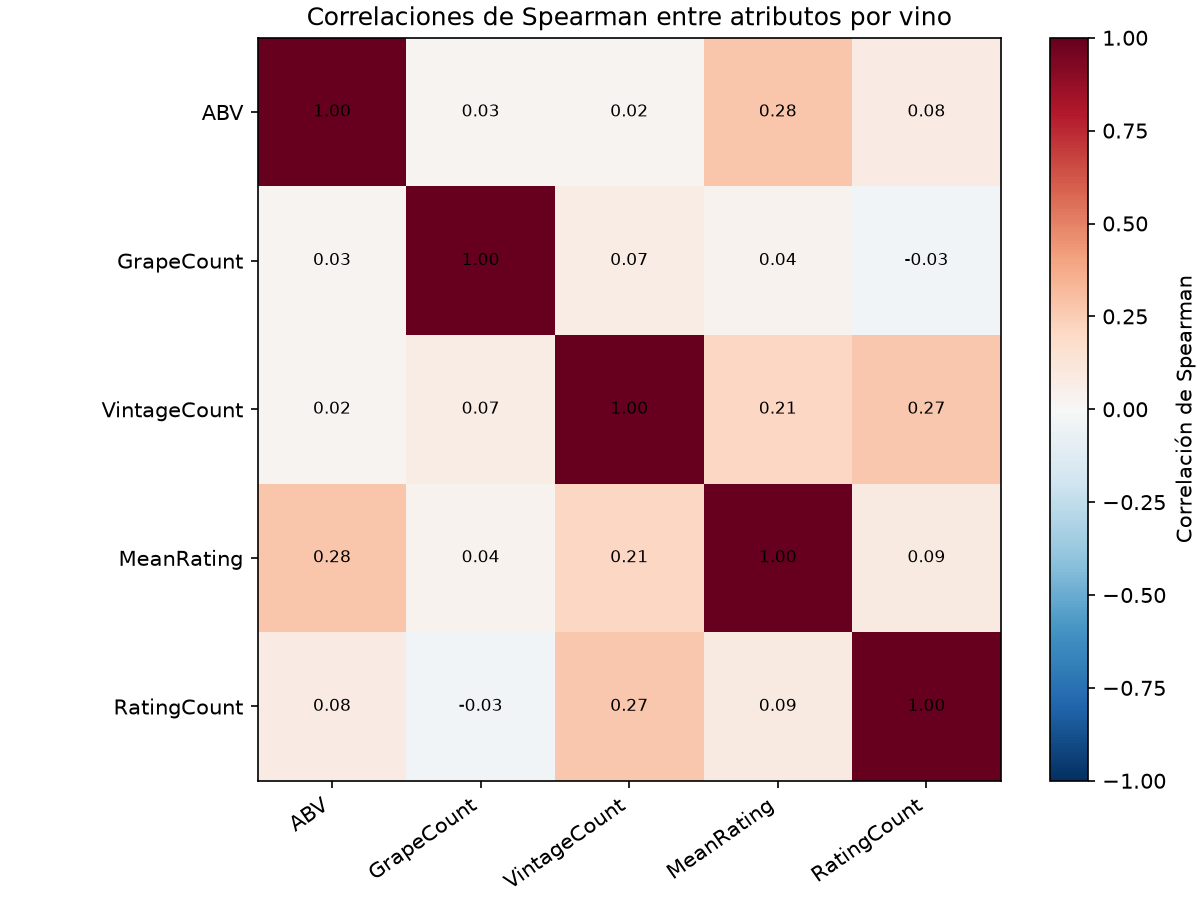

**Pairplot de atributos por vino**

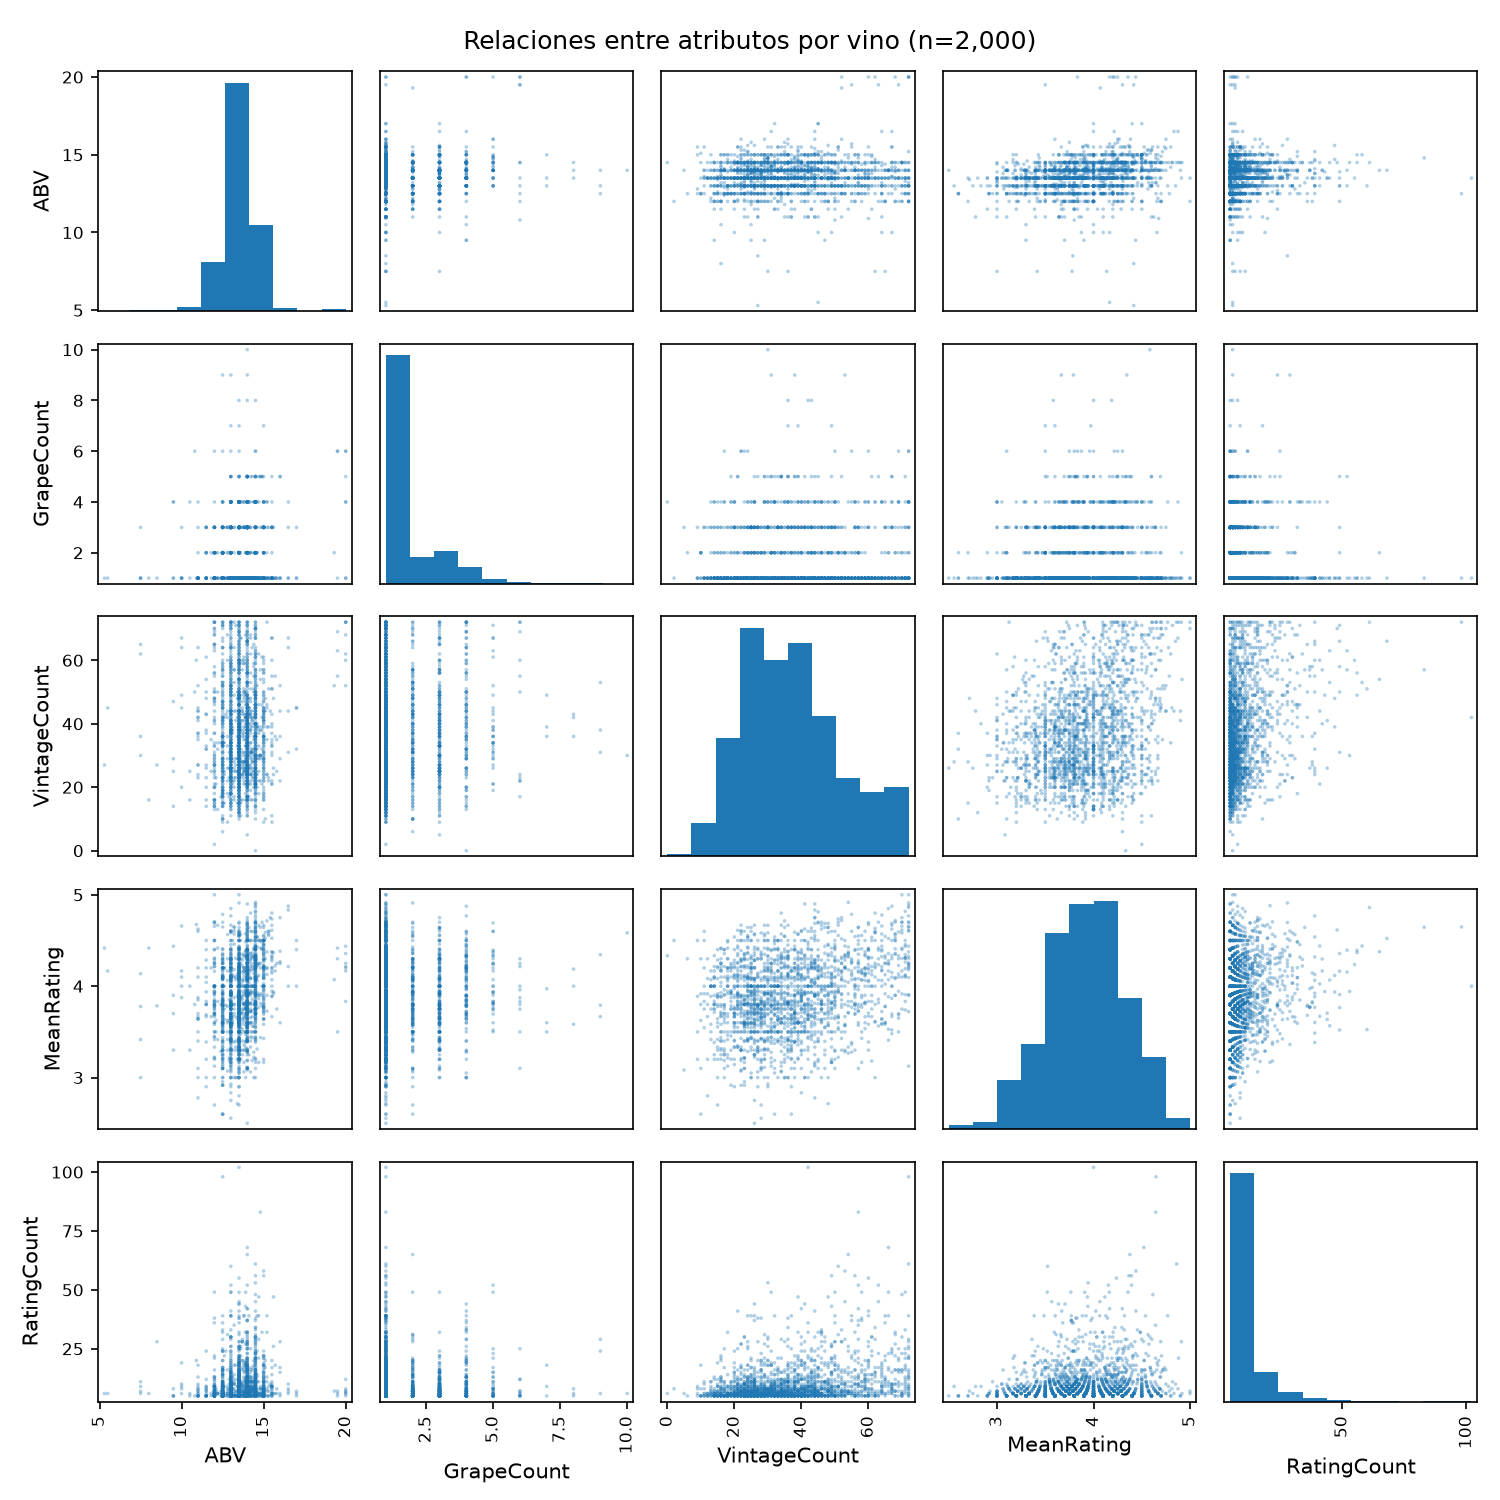

Resumen ABV vs rating medio: {'wine_count': 4746, 'minimum_ratings_per_wine': 5, 'spearman_rho': 0.27854297922370647, 'interpretation_scope': 'descriptive_association_in_rating_sample'}
Matriz de correlación de Spearman:


,ABV,GrapeCount,VintageCount,MeanRating,RatingCount
ABV,1.000000,0.028919,0.024154,0.278543,0.084104
GrapeCount,0.028919,1.000000,0.074071,0.038223,-0.030120
VintageCount,0.024154,0.074071,1.000000,0.207613,0.272613
MeanRating,0.278543,0.038223,0.207613,1.000000,0.086576
RatingCount,0.084104,-0.030120,0.272613,0.086576,1.000000


In [8]:
display(Markdown("""## 8. Análisis bivariante y multivariante

El análisis bivariante compara ratings y categorías del catálogo. Para ABV frente a rating medio, cada punto representa un vino con al menos cinco ratings en la muestra; la correlación de Spearman describe asociación monotónica, no causalidad. Las barras por tipo y país muestran la media junto al número de ratings; se omiten grupos con menos de 20.

El análisis multivariante usa una fila por vino y las variables ABV, número de uvas, número de añadas, rating medio y número de ratings. Los IDs quedan fuera porque no representan cantidades. La matriz presenta correlaciones de Spearman; el pairplot muestra hasta 2.000 vinos para mantener la figura legible."""))

for stem, caption in [
    ('rating_by_type', 'Rating medio por tipo de vino'),
    ('rating_by_country', 'Rating medio por país'),
    ('abv_vs_mean_rating', 'Relación bivariante: ABV y rating medio'),
    ('wine_feature_correlation', 'Heatmap multivariante de correlaciones'),
    ('wine_feature_pairplot', 'Pairplot de atributos por vino'),
]:
    display(Markdown(f'**{caption}**'))
    display_figure(stem)

print('Resumen ABV vs rating medio:', metrics['bivariate']['abv_vs_mean_rating'])
print('Matriz de correlación de Spearman:')
display(pd.DataFrame(metrics['multivariate']['spearman_correlation']).T)

### Hipótesis estadística y decisión
Pregunta: ¿la distribución de puntuaciones difiere entre tipos de vino?

- **H₀:** la distribución de `Rating` es igual entre los tipos comparados.
- **H₁:** al menos un tipo presenta una distribución distinta.
- **Nivel previsto:** α = 0,05.
- **Prueba posible:** Kruskal–Wallis, por puntuación ordinal/acotada y grupos independientes.

No se calcula un p-valor en esta versión: un mismo usuario puede aparecer varias veces, por lo que la independencia de observaciones no está garantizada; además, los ratings se muestrean por fila y no se controla el agrupamiento por usuario. El contraste respondería sobre distribuciones, no demostraría causalidad ni calidad intrínseca. Para una inferencia defendible habría que modelar la dependencia por usuario y reportar tamaño de efecto e intervalo de confianza.

## 9. Hallazgos calculados
Los valores de esta sección se construyen desde los informes ejecutados, no se escriben como resultados supuestos.

In [6]:
completeness = metrics['catalog']['completeness']
worst = sorted(completeness.items(), key=lambda item: item[1]['missing_percent'], reverse=True)[:3]
validation = json.loads((ROOT / 'reports' / 'data_quality' / 'validation_report.json').read_text(encoding='utf-8'))
display(Markdown(f"- El catálogo contiene **{wine_profile['row_count']:,}** filas y **{wine_profile['column_count']}** columnas; los IDs duplicados de vino son **{wine_profile['duplicate_identifier_rows'].get('WineID', 0)}**."))
display(Markdown('- Los atributos con mayor porcentaje de ausencias son: ' + ', '.join(f"`{name}` ({values['missing_percent']:.2f}%)" for name, values in worst) + '.'))
display(Markdown(f"- En la muestra uniforme de {rating_profile['row_count']:,} ratings, la media es **{metrics['ratings_sample']['rating_describe']['mean']:.3f}** y la mediana **{metrics['ratings_sample']['rating_describe']['50%']:.3f}**; no se extrapola al conjunto completo."))
display(Markdown(f"- La regla IQR marca **{metrics['catalog']['numeric_iqr']['ABV']['outlier_count']:,}** valores de ABV para inspección, sin eliminarlos."))
display(Markdown(f"- La muestra enlaza **{validation['ratings']['wine_id_match_rate']:.1%}** de sus ratings con el catálogo; no hay fechas inválidas ni puntuaciones fuera de rango."))
display(Markdown('- La cobertura, errores de parseo y candidatos de nombres se guardan en `reports/data_quality/` para revisión.'))

- El catálogo contiene **100,646** filas y **17** columnas; los IDs duplicados de vino son **0**.

- Los atributos con mayor porcentaje de ausencias son: `Website` (17.75%), `ABV` (0.00%), `Body` (0.00%).

- En la muestra uniforme de 100,000 ratings, la media es **3.883** y la mediana **4.000**; no se extrapola al conjunto completo.

- La regla IQR marca **3,462** valores de ABV para inspección, sin eliminarlos.

- La muestra enlaza **100.0%** de sus ratings con el catálogo; no hay fechas inválidas ni puntuaciones fuera de rango.

- La cobertura, errores de parseo y candidatos de nombres se guardan en `reports/data_quality/` para revisión.

## 10. Limitaciones
- Se leen todas las filas por bloques para obtener una muestra aleatoria sin sesgo de orden; solo se conservan y analizan 100.000 ratings.
- Las medias de vinos o usuarios con pocos registros tienen alta incertidumbre; popularidad no equivale a calidad.
- ABV fuera de los límites IQR puede ser extremo legítimo o error; se exportan ejemplos para inspección, sin borrado automático.
- Los atributos ausentes reflejan cobertura de la fuente y no se imputan globalmente.
- La similitud de nombres genera candidatos, no equivalencias confirmadas.
- No se ejecuta contraste estadístico al no controlar la dependencia de observaciones por usuario.
- Las condiciones comerciales de terceros deben comprobarse antes de una integración de producto.

## 11. Conclusiones y próximos pasos
La entrega deja un catálogo normalizado con IDs y procedencia preservados, controles de calidad y diagnósticos visuales de extremos. Antes de construir recomendaciones, conviene asegurar la licencia, enriquecer atributos incompletos y revisar manualmente candidatos de duplicado. La muestra uniforme permite un análisis exploratorio de ratings, pero sus asociaciones son descriptivas y no controlan la dependencia entre puntuaciones del mismo usuario. El diseño mantiene las valoraciones X-Wines separadas de las futuras valoraciones MySumiller.

### Resumen ejecutivo para exposición
Presentar primero la calidad y completitud del catálogo; después, la distribución de ABV y las relaciones bivariantes/multivariantes observadas. Aclarar que el análisis de ratings se basa en una muestra de 100.000 observaciones, no en agregaciones de los 21 millones, y que las asociaciones no implican causalidad.